In [1]:
import sys
from pathlib import Path

# Add project root so `import shared` works
root = Path.cwd().resolve()
while root != root.parent and not (root / "shared").exists():
    root = root.parent
if not (root / "shared").exists():
    raise RuntimeError("Could not find project root containing 'shared/'")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from shared.paths import get_experiment_paths
from shared.visualization import show_grid, save_grid

import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [2]:
def latest_ckpt(models_dir):
    ckpts = sorted(models_dir.glob("ckpt_epoch_*.pth"))
    if not ckpts:
        raise FileNotFoundError(f"No ckpt_epoch_*.pth found in {models_dir}")
    return ckpts[-1]

In [3]:
import torch.nn as nn

class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.ReLU(True),
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.Linear(512, 1024),
            nn.ReLU(True),
            nn.Linear(1024, 28*28),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.net(z)
        return x.view(-1, 1, 28, 28)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(28*28, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x).view(-1)

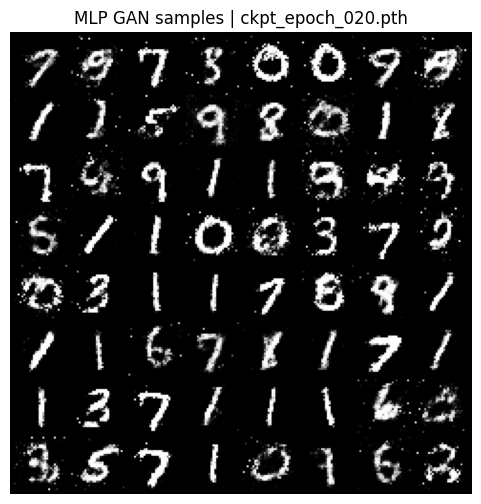

In [4]:
paths = get_experiment_paths("01_mlp_gan")

ckpt_path = latest_ckpt(paths.models_dir)
ckpt = torch.load(ckpt_path, map_location=device)

z_dim = ckpt.get("z_dim", 100)

G = Generator(z_dim=z_dim).to(device)
D = Discriminator().to(device)

G.load_state_dict(ckpt["G"])
D.load_state_dict(ckpt["D"])

G.eval()

with torch.no_grad():
    z = torch.randn(64, z_dim, device=device)
    samples = G(z)

show_grid(samples, title=f"MLP GAN samples | {ckpt_path.name}")